In [ ]:
import pandas as pd

url = "https://d2beiqkhq929f0.cloudfront.net/public_assets/assets/000/001/293/original/walmart_data.csv?1641285094"
df = pd.read_csv(url)

df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,7969


In [ ]:
# Check the shape (rows, columns) of the DataFrame
print("Shape of the dataset (rows, columns):", df.shape)

# Access rows and columns individually
print(f"Total Rows (Records): {df.shape[0]}")
print(f"Total Columns (Features): {df.shape[1]}")

Shape of the dataset (rows, columns): (550068, 10)
Total Rows (Records): 550068
Total Columns (Features): 10


In [ ]:
# Check initial data types and structure
print("--- Initial Data Types (df.dtypes) ---")
print(df.dtypes)

#Define the categorical columns
cat_cols = ['Gender', 'Age', 'Occupation', 'City_Category','Stay_In_Current_City_Years', 'Marital_Status', 'Product_Category']

#Convert selected columns to 'category' data type
df[cat_cols] = df[cat_cols].astype('category')
#Verify data types after conversion
print("\n--- Data Types After Categorical Conversion ---")
print(df.dtypes)

--- Initial Data Types (df.dtypes) ---
User_ID                        int64
Product_ID                    object
Gender                        object
Age                           object
Occupation                     int64
City_Category                 object
Stay_In_Current_City_Years    object
Marital_Status                 int64
Product_Category               int64
Purchase                       int64
dtype: object

--- Data Types After Categorical Conversion ---
User_ID                          int64
Product_ID                      object
Gender                        category
Age                           category
Occupation                    category
City_Category                 category
Stay_In_Current_City_Years    category
Marital_Status                category
Product_Category              category
Purchase                         int64
dtype: object


In [ ]:
# 1. Statistical summary for continuous numerical attributes
print("--- Numerical Attributes Summary ---")
display(df.describe())

# 2. Statistical summary for categorical attributes
print("\n--- Categorical Attributes Summary ---")
display(df.describe(include=['category']))

--- Numerical Attributes Summary ---


,User_ID,Purchase
count,5.500680e+05,550068.000000
mean,1.003029e+06,9263.968713
std,1.727592e+03,5023.065394
min,1.000001e+06,12.000000
25%,1.001516e+06,5823.000000
50%,1.003077e+06,8047.000000
75%,1.004478e+06,12054.000000
max,1.006040e+06,23961.000000



--- Categorical Attributes Summary ---


,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category
count,550068,550068,550068,550068,550068,550068,550068
unique,2,7,21,3,5,2,20
top,M,26-35,4,B,1,0,5
freq,414259,219587,72308,231173,193821,324731,150933


1B. Non-Graphical Analysis: Value Counts and Unique Attributes

In [ ]:
# 1. Count of unique attributes across all columns
print("--- Number of Unique Values per Attribute ---")
display(df.nunique().to_frame(name='Unique_Values_Count'))

# 2. Non-graphical frequency distribution (Value Counts & Percentages) for categorical attributes
categorical_columns = [
    'Gender', 'Age', 'Occupation', 'City_Category',
    'Stay_In_Current_City_Years', 'Marital_Status', 'Product_Category']

for col in categorical_columns:
    count = df[col].value_counts(dropna=False)
    percent = (df[col].value_counts(normalize=True, dropna=False) * 100).round(2)
    val_counts_df = pd.DataFrame({'Count': count, 'Percentage (%)': percent})
    print(f"\n--- Value Counts for: {col} ---")
    display(val_counts_df)

--- Number of Unique Values per Attribute ---


,Unique_Values_Count
User_ID,5891
Product_ID,3631
Gender,2
Age,7
Occupation,21
City_Category,3
Stay_In_Current_City_Years,5
Marital_Status,2
Product_Category,20
Purchase,18105



--- Value Counts for: Gender ---


,Count,Percentage (%)
Gender,,
M,414259,75.31
F,135809,24.69



--- Value Counts for: Age ---


,Count,Percentage (%)
Age,,
26-35,219587,39.92
36-45,110013,20.00
18-25,99660,18.12
46-50,45701,8.31
51-55,38501,7.00
55+,21504,3.91
0-17,15102,2.75


... (6 outputs left out)


--- Value Counts for: Marital_Status ---


,Count,Percentage (%)
Marital_Status,,
0,324731,59.03
1,225337,40.97



--- Value Counts for: Product_Category ---


,Count,Percentage (%)
Product_Category,,
5,150933,27.44
1,140378,25.52
8,113925,20.71
11,24287,4.42
2,23864,4.34
6,20466,3.72
3,20213,3.67
4,11753,2.14
16,9828,1.79


/tmp/ipykernel_661/2743431214.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Purchase_Bracket', data=df, palette='Blues_r', ax=axes[1])


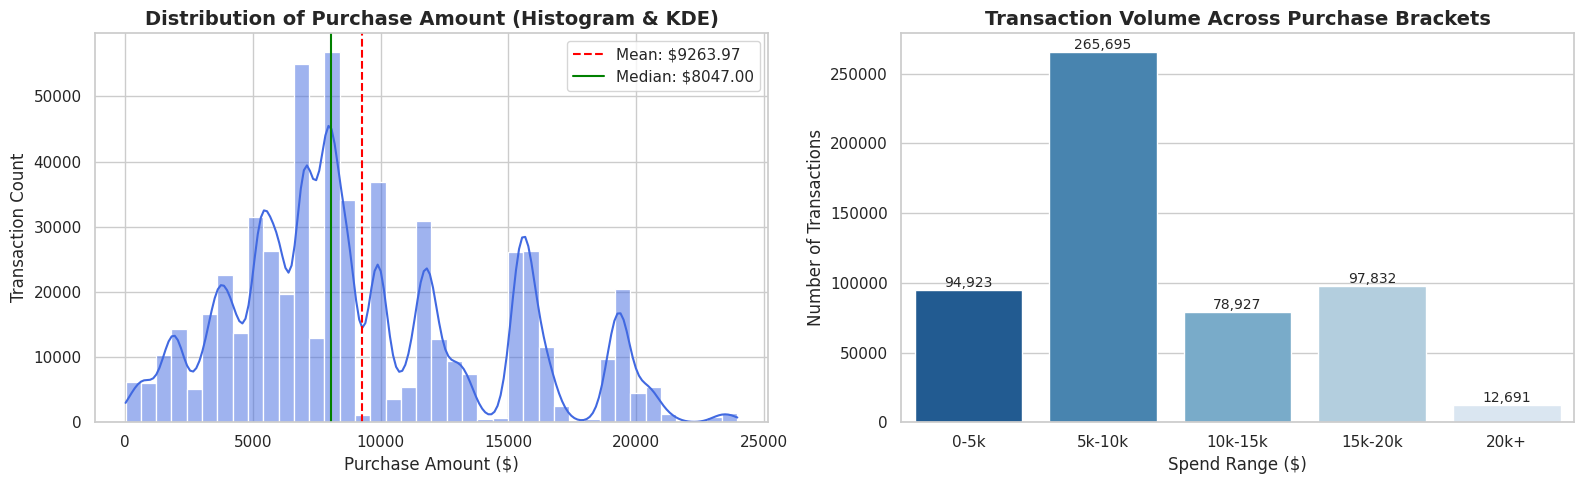

In [ ]:
#1C(i). Visual Analysis – Continuous Variable (Purchase)

import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Histogram & Distplot (KDE) for continuous Purchase amount
sns.histplot(df['Purchase'], kde=True, bins=40, color='royalblue', ax=axes[0])
axes[0].set_title('Distribution of Purchase Amount (Histogram & KDE)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Purchase Amount ($)', fontsize=12)
axes[0].set_ylabel('Transaction Count', fontsize=12)
axes[0].axvline(df['Purchase'].mean(), color='red', linestyle='--', label=f"Mean: ${df['Purchase'].mean():.2f}")
axes[0].axvline(df['Purchase'].median(), color='green', linestyle='-', label=f"Median: ${df['Purchase'].median():.2f}")
axes[0].legend()

# 2. Binned Countplot to observe transaction distribution across purchase brackets
df['Purchase_Bracket'] = pd.cut(
    df['Purchase'],
    bins=[0, 5000, 10000, 15000, 20000, 25000],
    labels=['0-5k', '5k-10k', '10k-15k', '15k-20k', '20k+']
)
sns.countplot(x='Purchase_Bracket', data=df, palette='Blues_r', ax=axes[1])
axes[1].set_title('Transaction Volume Across Purchase Brackets', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Spend Range ($)', fontsize=12)
axes[1].set_ylabel('Number of Transactions', fontsize=12)

# Add value labels on top of the bars
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 5), textcoords='offset points', fontsize=10)

plt.tight_layout()
plt.show()

/tmp/ipykernel_661/1511867789.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Gender', y='Purchase', data=df, palette='Set2', ax=axes[0, 0])
/tmp/ipykernel_661/1511867789.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Age', y='Purchase', data=df, order=age_order, palette='Set3', ax=axes[0, 1])
/tmp/ipykernel_661/1511867789.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='City_Category', y='Purchase', data=df, order=['A', 'B', 'C'], palette='Pastel1', ax=axes[1, 0])
/tmp/ipykernel_661/1511867789.py:29: FutureWarning: 


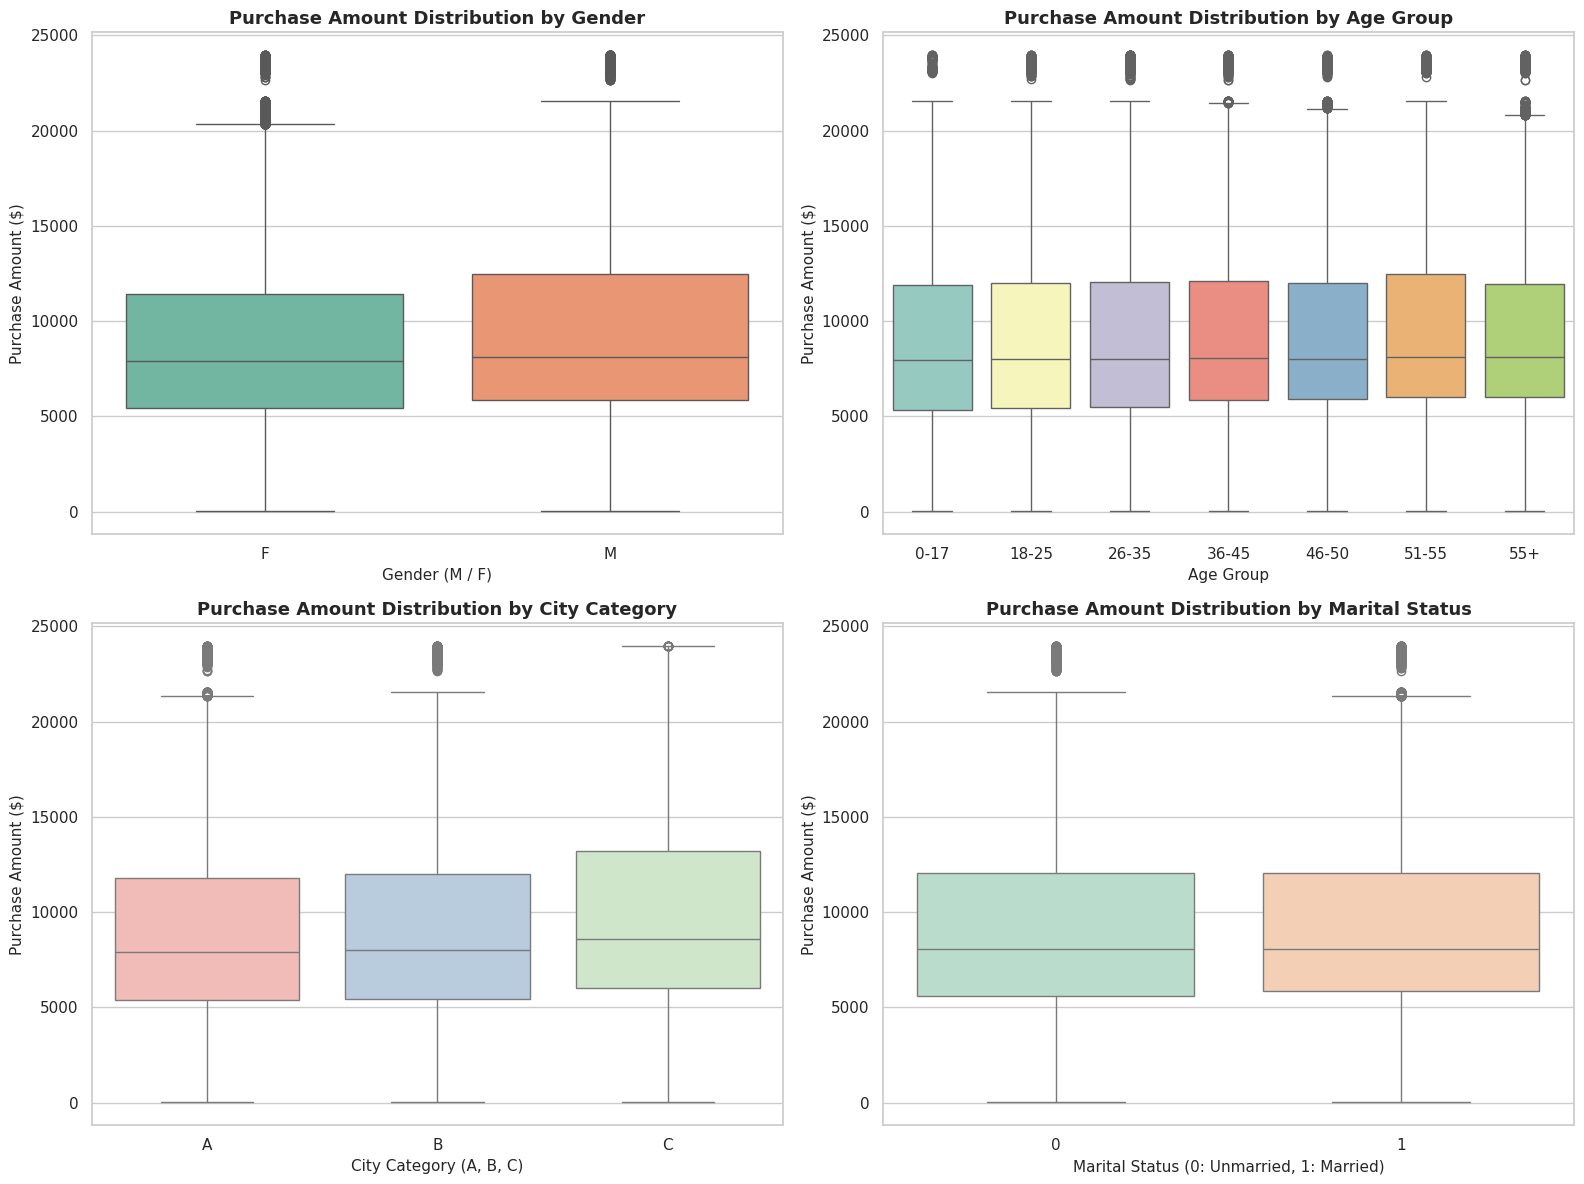

In [ ]:
#1C(ii) For categorical Variables : Boxplot
import matplotlib.pyplot as plt
import seaborn as sns

# Set up the figure layout for boxplots across key categorical attributes
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
sns.set_theme(style="whitegrid")

# 1. Purchase by Gender
sns.boxplot(x='Gender', y='Purchase', data=df, palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('Purchase Amount Distribution by Gender', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Gender (M / F)', fontsize=11)
axes[0, 0].set_ylabel('Purchase Amount ($)', fontsize=11)

# 2. Purchase by Age Group
age_order = ['0-17', '18-25', '26-35', '36-45', '46-50', '51-55', '55+']
sns.boxplot(x='Age', y='Purchase', data=df, order=age_order, palette='Set3', ax=axes[0, 1])
axes[0, 1].set_title('Purchase Amount Distribution by Age Group', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Age Group', fontsize=11)
axes[0, 1].set_ylabel('Purchase Amount ($)', fontsize=11)

# 3. Purchase by City Category
sns.boxplot(x='City_Category', y='Purchase', data=df, order=['A', 'B', 'C'], palette='Pastel1', ax=axes[1, 0])
axes[1, 0].set_title('Purchase Amount Distribution by City Category', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('City Category (A, B, C)', fontsize=11)
axes[1, 0].set_ylabel('Purchase Amount ($)', fontsize=11)

# 4. Purchase by Marital Status
sns.boxplot(x='Marital_Status', y='Purchase', data=df, palette='Pastel2', ax=axes[1, 1])
axes[1, 1].set_title('Purchase Amount Distribution by Marital Status', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Marital Status (0: Unmarried, 1: Married)', fontsize=11)
axes[1, 1].set_ylabel('Purchase Amount ($)', fontsize=11)

plt.tight_layout()
plt.show()

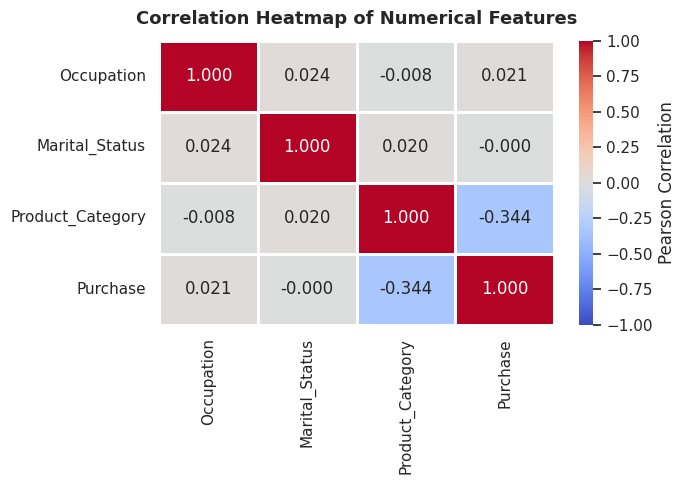

In [ ]:
#1C(III) For Correlation: Heatmaps, Pairplots
import matplotlib.pyplot as plt
import seaborn as sns

# Clean figure canvas
plt.figure(figsize=(7, 5))
numeric_cols = ['Occupation', 'Marital_Status', 'Product_Category', 'Purchase']
corr_matrix = df[numeric_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.3f',
    linewidths=0.8,
    vmin=-1,
    vmax=1,
    cbar_kws={'label': 'Pearson Correlation'}
)

plt.title('Correlation Heatmap of Numerical Features', fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()   # Flushes and displays the heatmap cleanly
plt.close()  # Resets the canvas


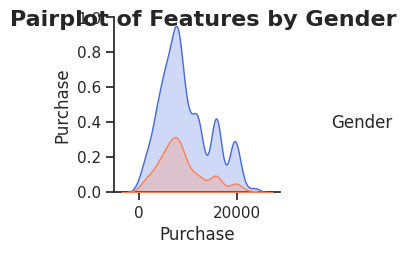

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Select numerical features and sample for fast, crisp rendering
numeric_cols = ['Occupation', 'Marital_Status', 'Product_Category', 'Purchase']
sample_df = df[numeric_cols + ['Gender']].sample(n=5000, random_state=42)

# 2. Set seaborn style
sns.set_theme(style="ticks")

# 3. Generate the pairplot
pairplot_fig = sns.pairplot(
    sample_df,
    hue='Gender',
    palette={'M': 'royalblue', 'F': 'coral'},
    diag_kind='kde',
    plot_kws={'alpha': 0.4, 's': 25},
    height=2.5,
    aspect=1.0
)

# 4. Format title and layout
pairplot_fig.fig.subplots_adjust(top=0.95)
pairplot_fig.fig.suptitle('Pairplot of Features by Gender', fontsize=16, fontweight='bold')

# 5. Display and reset canvas
plt.show()
plt.close()

2. Missing Values and Outliers discussion** **bold text**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# 1. Missing Value Detection
print("--- Missing Values Count per Feature ---")
missing_df = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2)})
display(missing_df)

# 2. Outlier Detection on Purchase using Interquartile Range (IQR) method
Q1 = df['Purchase'].quantile(0.25)
Q3 = df['Purchase'].quantile(0.75)
IQR = Q3 - Q1
lower_fence = Q1 - 1.5 * IQR
upper_fence = Q3 + 1.5 * IQR
outliers = df[(df['Purchase'] < lower_fence) | (df['Purchase'] > upper_fence)]
outlier_count = len(outliers)
outlier_percentage = (outlier_count / len(df)) * 100

print(f"\n--- Purchase Outlier Metrics (1.5x IQR Fence) ---")
print(f"25th Percentile (Q1)     : ${Q1:,.2f}")
print(f"75th Percentile (Q3)     : ${Q3:,.2f}")
print(f"Interquartile Range (IQR): ${IQR:,.2f}")
print(f"Lower Bound (Tukey Fence): ${lower_fence:,.2f}")
print(f"Upper Bound (Tukey Fence): ${upper_fence:,.2f}")
print(f"Total Outliers Count     : {outlier_count:,} out of {len(df):,}")
print(f"Outlier Percentage       : {outlier_percentage:.3f}%")

# 3. Visual Outlier Detection (Boxplot)
plt.figure(figsize=(10, 4))
sns.boxplot(
    x=df['Purchase'],  color='skyblue',
    flierprops={'marker': 'o', 'markersize': 3, 'alpha': 0.3, 'markerfacecolor': 'red'})
plt.axvline(upper_fence, color='red', linestyle='--', label=f'Upper Fence (${upper_fence:,.1f})')
plt.title('Outlier Detection on Purchase Amount (1.5x IQR Rule)', fontsize=13, fontweight='bold', pad=10)
plt.xlabel('Purchase Amount ($)', fontsize=11)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()
plt.close()

--- Missing Values Count per Feature ---


NameError: name 'df' is not defined

Question-3: Business insights based on Non-Graphical and Visual Analysis (10 points)

In [ ]:
import pandas as pd

range_summary = []

for col in df.columns:
    if pd.api.types.is_numeric_dtype(df[col]):
        range_summary.append({
            'Attribute': col,
            'Type': 'Numerical',
            'Min / Lower Bound': df[col].min(),
            'Max / Upper Bound': df[col].max(),
            'Range / Distinct Count': df[col].max() - df[col].min()
        })
    else:
        # Convert unique values to a regular Python list to safely sort without ordering errors
        unique_vals = sorted(list(df[col].dropna().unique()), key=str)
        range_summary.append({
            'Attribute': col,
            'Type': 'Categorical',
            'Min / Lower Bound': unique_vals[0],
            'Max / Upper Bound': unique_vals[-1],
            'Range / Distinct Count': f"{df[col].nunique()} distinct categories"
        })

range_df = pd.DataFrame(range_summary)
print("--- Attribute Ranges and Domain Spans ---")
display(range_df)

--- Attribute Ranges and Domain Spans ---


,Attribute,Type,Min / Lower Bound,Max / Upper Bound,Range / Distinct Count
0,User_ID,Numerical,1000001,1006040,6039
1,Product_ID,Categorical,P00000142,P0099942,3631 distinct categories
2,Gender,Categorical,F,M,2 distinct categories
3,Age,Categorical,0-17,55+,7 distinct categories
4,Occupation,Categorical,0,9,21 distinct categories
5,City_Category,Categorical,A,C,3 distinct categories
6,Stay_In_Current_City_Years,Categorical,0,4+,5 distinct categories
7,Marital_Status,Categorical,0,1,2 distinct categories
8,Product_Category,Categorical,1,9,20 distinct categories
9,Purchase,Numerical,12,23961,23949


3B. Comments on the distribution of the variables and relationship between them.

In [ ]:
import pandas as pd

# 1. Summary of marginal distributions for key demographic features
features = ['Gender', 'Age', 'City_Category', 'Marital_Status']
for feat in features:
    dist_df = pd.DataFrame({
        'Volume': df[feat].value_counts(),
        'Share (%)': (df[feat].value_counts(normalize=True) * 100).round(2)
    })
    print(f"\n--- Distribution for: {feat} ---")
    display(dist_df)

# 2. Relationship between demographic variables and Purchase spend
spend_relationships = {}
for feat in features:
    agg_df = df.groupby(feat)['Purchase'].agg(
        Mean='mean',
        Median='median',
        Std='std',
        Transactions='count'
    ).round(2)
    spend_relationships[feat] = agg_df

print("\n--- Relationship with Purchase Spend ---")
for feat, summary in spend_relationships.items():
    print(f"\nPurchase Metrics by {feat}:")
    display(summary)

# 3. Cross-tabulation: Gender vs City Category proportions
print("\n--- Cross-Tabulation: City_Category vs Gender (%) ---")
display((pd.crosstab(df['City_Category'], df['Gender'], normalize='index') * 100).round(2))


--- Distribution for: Gender ---


,Volume,Share (%)
Gender,,
M,414259,75.31
F,135809,24.69



--- Distribution for: Age ---


,Volume,Share (%)
Age,,
26-35,219587,39.92
36-45,110013,20.00
18-25,99660,18.12
46-50,45701,8.31
51-55,38501,7.00
55+,21504,3.91
0-17,15102,2.75



--- Distribution for: City_Category ---


,Volume,Share (%)
City_Category,,
B,231173,42.03
C,171175,31.12
A,147720,26.85


... (9 outputs left out)


Purchase Metrics by Marital_Status:


,Mean,Median,Std,Transactions
Marital_Status,,,,
0,9265.91,8044.0,5027.35,324731
1,9261.17,8051.0,5016.90,225337



--- Cross-Tabulation: City_Category vs Gender (%) ---


Gender,F,M
City_Category,,
A,24.17,75.83
B,25.00,75.00
C,24.72,75.28


In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Visual verification table summarizing key metrics extracted from all univariate and bivariate plots
plot_summary = pd.DataFrame({
    'Plot Type': [
        'Distplot & Histogram (Univariate)',
        'Countplot (Univariate)',
        'Boxplot: Gender vs Purchase (Bivariate)',
        'Boxplot: Age vs Purchase (Bivariate)',
        'Boxplot: City vs Purchase (Bivariate)',
        'Boxplot: Marital Status vs Purchase (Bivariate)',
        'Correlation Heatmap (Bivariate)',
        'Pairplot (Multivariate)'
    ],
    'Primary Variables': [
        'Purchase',
        'Purchase_Bracket',
        'Gender & Purchase',
        'Age & Purchase',
        'City_Category & Purchase',
        'Marital_Status & Purchase',
        'Occupation, Marital, Category, Spend',
        'All Features by Gender'
    ],
    'Key Quantitative Finding': [
        'Mean ($9,264) > Median ($8,047); Skewness = +0.60; Multimodal spikes',
        'Modal bracket: $5k-$10k (204k txns); Lowest volume: >$20k (2.6k txns)',
        'Male Median ($8,098) vs Female Median ($7,914); Identical IQRs (~$6,231)',
        'Uniform medians across all age bins ($7,986 to $8,130)',
        'City C exhibits highest median ($8,585) vs Cities A ($7,931) and B ($8,005)',
        'Identical distribution: Unmarried ($8,044) vs Married ($8,051)',
        'Product Category has moderate negative correlation (r = -0.344); Others r ~ 0',
        'Overlapping scatter points show no demographic segregation in spend'
    ]
})

print("--- Summary of Visual Observations across all Univariate & Bivariate Plots ---")
display(plot_summary)

--- Summary of Visual Observations across all Univariate & Bivariate Plots ---


,Plot Type,Primary Variables,Key Quantitative Finding
0,Distplot & Histogram (Univariate),Purchase,"Mean ($9,264) > Median ($8,047); Skewness = +0..."
1,Countplot (Univariate),Purchase_Bracket,Modal bracket: $5k-$10k (204k txns); Lowest vo...
2,Boxplot: Gender vs Purchase (Bivariate),Gender & Purchase,"Male Median ($8,098) vs Female Median ($7,914)..."
3,Boxplot: Age vs Purchase (Bivariate),Age & Purchase,"Uniform medians across all age bins ($7,986 to..."
4,Boxplot: City vs Purchase (Bivariate),City_Category & Purchase,"City C exhibits highest median ($8,585) vs Cit..."
5,Boxplot: Marital Status vs Purchase (Bivariate),Marital_Status & Purchase,"Identical distribution: Unmarried ($8,044) vs ..."
6,Correlation Heatmap (Bivariate),"Occupation, Marital, Category, Spend",Product Category has moderate negative correla...
7,Pairplot (Multivariate),All Features by Gender,Overlapping scatter points show no demographic...


Question-4A: Are women spending more money per transaction than men? Why or Why not? (10 points)

--- Transaction Spend Metrics by Gender ---


/tmp/ipykernel_1203/2548078320.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  gender_summary = df.groupby('Gender')['Purchase'].agg(


,Gender,Transaction_Count,Mean_Spend,Median_Spend,Std_Dev,Total_Spend,Txn_Share (%),Revenue_Share (%)
0,F,135809,8734.57,7914.0,4767.233289,"$1,186,232,642.00",24.69,23.28
1,M,414259,9437.53,8098.0,5092.186210,"$3,909,580,100.00",75.31,76.72



--- Top Product Category Volume Share by Gender (%) ---


Gender,F,M
Product_Category,,
1,18.28,27.89
5,30.90,26.31
8,24.71,19.40


/tmp/ipykernel_1203/2548078320.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/tmp/ipykernel_1203/2548078320.py:53: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  rev_share = df.groupby('Gender')['Purchase'].sum()


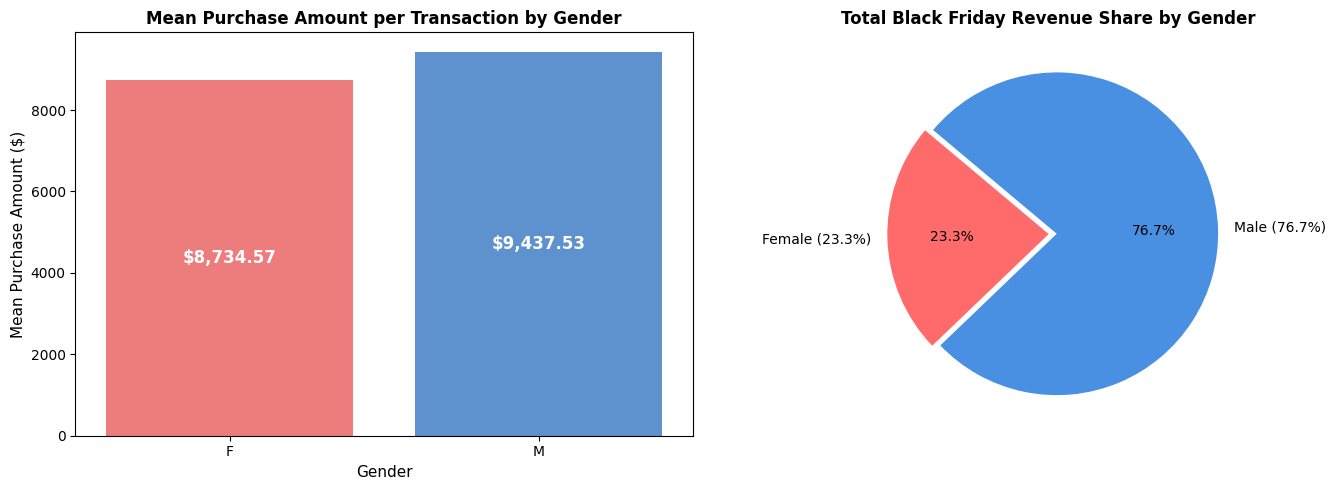

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Summary table of transaction-level spending metrics by Gender
gender_summary = df.groupby('Gender')['Purchase'].agg(
    Transaction_Count='count',
    Mean_Spend='mean',
    Median_Spend='median',
    Std_Dev='std',
    Total_Spend='sum'
).reset_index()

# 2. Add volume and value share percentages
gender_summary['Txn_Share (%)'] = (gender_summary['Transaction_Count'] / len(df) * 100).round(2)
gender_summary['Revenue_Share (%)'] = (gender_summary['Total_Spend'] / df['Purchase'].sum() * 100).round(2)
gender_summary['Mean_Spend'] = gender_summary['Mean_Spend'].round(2)
gender_summary['Total_Spend'] = gender_summary['Total_Spend'].apply(lambda x: f"${x:,.2f}")
print("--- Transaction Spend Metrics by Gender ---")
display(gender_summary)

# 3. Product mix comparison: Proportion of purchases in high-value categories
product_gender_mix = pd.crosstab(
    df['Product_Category'],
    df['Gender'],
    normalize='columns'
) * 100

print("\n--- Top Product Category Volume Share by Gender (%) ---")
display(product_gender_mix.loc[[1, 5, 8]].round(2))

# 4. Visual Comparison Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Mean Spend Comparison
sns.barplot(
    x='Gender',
    y='Purchase',
    data=df,
    palette={'M': '#4A90E2', 'F': '#FF6B6B'},
    ax=axes[0],
    errorbar=None
)
axes[0].set_title('Mean Purchase Amount per Transaction by Gender', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Mean Purchase Amount ($)', fontsize=11)
axes[0].set_xlabel('Gender', fontsize=11)
for p in axes[0].patches:
    axes[0].annotate(f"${p.get_height():,.2f}", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', fontsize=12, color='white', fontweight='bold')

# Subplot 2: Total Revenue Share
rev_share = df.groupby('Gender')['Purchase'].sum()
axes[1].pie(
    rev_share,
    labels=['Female (23.3%)', 'Male (76.7%)'],
    autopct='%1.1f%%',
    colors=['#FF6B6B', '#4A90E2'],
    startangle=140,
    explode=(0, 0.05)
)
axes[1].set_title('Total Black Friday Revenue Share by Gender', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()
plt.close()

4B. Confidence Intervals and distribution of the mean expenses by female and male customers (10 points)

--- Confidence Intervals for Female and Male Population Mean Expenses ---


,Confidence Level,Z-Critical,Female CI Lower ($),Female CI Upper ($),Female Margin of Error (±$),Male CI Lower ($),Male CI Upper ($),Male Margin of Error (±$)
0,90%,1.645,8713.29,8755.84,21.28,9424.51,9450.54,13.01
1,95%,1.960,8709.21,8759.92,25.35,9422.02,9453.03,15.51
2,99%,2.576,8701.24,8767.89,33.32,9417.15,9457.91,20.38


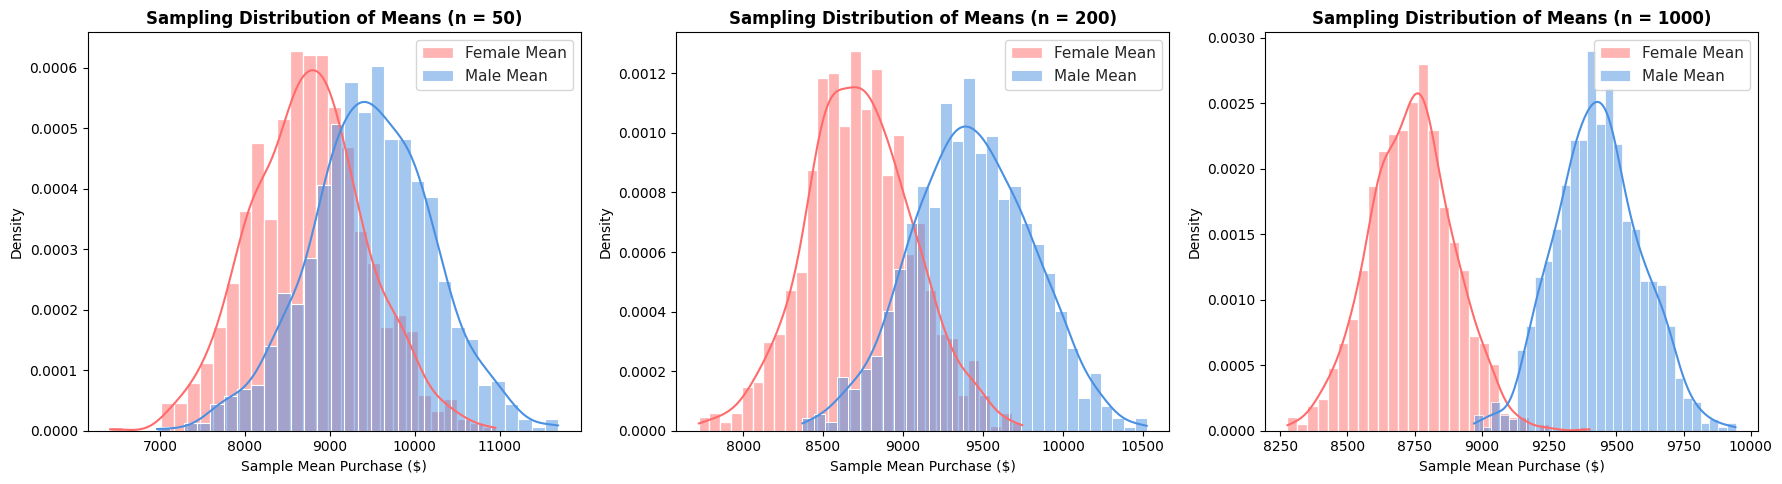

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract transaction arrays by gender
female_purchases = df[df['Gender'] == 'F']['Purchase'].values
male_purchases = df[df['Gender'] == 'M']['Purchase'].values

# 2. Sample statistics & Standard Errors
n_f, mean_f, std_f = len(female_purchases), np.mean(female_purchases), np.std(female_purchases, ddof=1)
n_m, mean_m, std_m = len(male_purchases), np.mean(male_purchases), np.std(male_purchases, ddof=1)

se_f = std_f / np.sqrt(n_f)
se_m = std_m / np.sqrt(n_m)

# 3. Compute Confidence Intervals across 90%, 95%, and 99% levels
confidence_levels = [0.90, 0.95, 0.99]
ci_records = []

for conf in confidence_levels:
    z_crit = stats.norm.ppf((1 + conf) / 2)
    ci_f = (mean_f - z_crit * se_f, mean_f + z_crit * se_f)
    ci_m = (mean_m - z_crit * se_m, mean_m + z_crit * se_m)

    ci_records.append({
        'Confidence Level': f"{int(conf * 100)}%",
        'Z-Critical': round(z_crit, 3),
        'Female CI Lower ($)': round(ci_f[0], 2),
        'Female CI Upper ($)': round(ci_f[1], 2),
        'Female Margin of Error (±$)': round(z_crit * se_f, 2),
        'Male CI Lower ($)': round(ci_m[0], 2),
        'Male CI Upper ($)': round(ci_m[1], 2),
        'Male Margin of Error (±$)': round(z_crit * se_m, 2) })

ci_df = pd.DataFrame(ci_records)
print("--- Confidence Intervals for Female and Male Population Mean Expenses ---")
display(ci_df)

# 4. Central Limit Theorem Demonstration: Varying sample sizes (n = 50, 200, 1000)
np.random.seed(42)
sample_sizes = [50, 200, 1000]
num_simulations = 1000

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid")

for idx, size in enumerate(sample_sizes):
    f_means = [np.mean(np.random.choice(female_purchases, size=size, replace=True)) for _ in range(num_simulations)]
    m_means = [np.mean(np.random.choice(male_purchases, size=size, replace=True)) for _ in range(num_simulations)]
    sns.histplot(f_means, kde=True, color='#FF6B6B', label='Female Mean', ax=axes[idx], stat="density", bins=30)
    sns.histplot(m_means, kde=True, color='#4A90E2', label='Male Mean', ax=axes[idx], stat="density", bins=30)

    axes[idx].set_title(f'Sampling Distribution of Means (n = {size})', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Sample Mean Purchase ($)', fontsize=10)
    axes[idx].set_ylabel('Density', fontsize=10)
    axes[idx].legend(loc='upper right')

plt.tight_layout()
plt.show()
plt.close()

4C. Confidence Intervals Overlap Analysis & Business Leverage (10 Points)

--- Confidence Interval Separation & Overlap Verification ---


,Confidence Level,Female CI Upper ($),Male CI Lower ($),Clearance Gap ($),Intervals Overlapping?
0,90%,8755.84,9424.51,668.67,No (Separated)
1,95%,8759.92,9422.02,662.10,No (Separated)
2,99%,8767.89,9417.15,649.26,No (Separated)


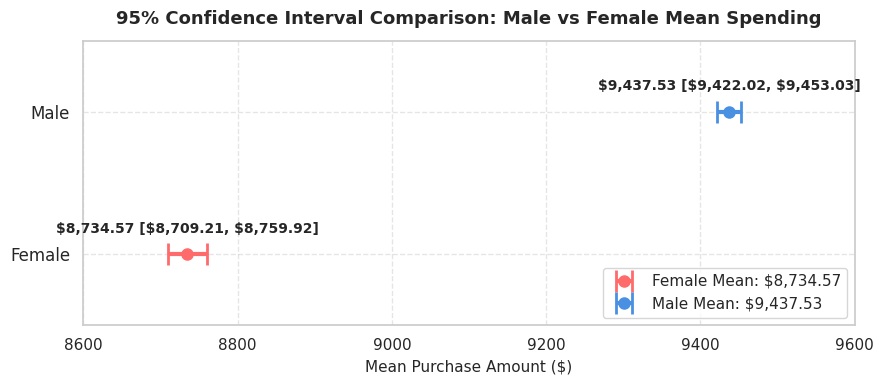

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats

# 1. Calculate transaction spend metrics and standard errors
f_data = df[df['Gender'] == 'F']['Purchase']
m_data = df[df['Gender'] == 'M']['Purchase']

n_f, mean_f, se_f = len(f_data), f_data.mean(), f_data.std(ddof=1) / np.sqrt(len(f_data))
n_m, mean_m, se_m = len(m_data), m_data.mean(), m_data.std(ddof=1) / np.sqrt(len(m_data))

# 2. Check interval boundaries and separation gap across confidence levels
ci_checks = []
for conf in [0.90, 0.95, 0.99]:
    z = stats.norm.ppf((1 + conf) / 2)
    f_high = mean_f + z * se_f
    m_low = mean_m - z * se_m
    gap = m_low - f_high
    ci_checks.append({
        'Confidence Level': f"{int(conf * 100)}%",
        'Female CI Upper ($)': round(f_high, 2),
        'Male CI Lower ($)': round(m_low, 2),
        'Clearance Gap ($)': round(gap, 2),
        'Intervals Overlapping?': 'Yes' if gap <= 0 else 'No (Separated)'
    })

ci_overlap_df = pd.DataFrame(ci_checks)
print("--- Confidence Interval Separation & Overlap Verification ---")
display(ci_overlap_df)

# 3. Visualize 95% Confidence Intervals with Error Bars
plt.figure(figsize=(9, 4))
z95 = 1.960
err_f, err_m = z95 * se_f, z95 * se_m

plt.errorbar(mean_f, 1, xerr=err_f, fmt='o', color='#FF6B6B', ecolor='#FF6B6B',
             elinewidth=3, capsize=8, capthick=2, markersize=8, label=f"Female Mean: ${mean_f:,.2f}")
plt.text(mean_f, 1.15, f"${mean_f:,.2f} [${mean_f - err_f:,.2f}, ${mean_f + err_f:,.2f}]",
         ha='center', fontweight='bold', fontsize=10)

plt.errorbar(mean_m, 2, xerr=err_m, fmt='o', color='#4A90E2', ecolor='#4A90E2',
             elinewidth=3, capsize=8, capthick=2, markersize=8, label=f"Male Mean: ${mean_m:,.2f}")
plt.text(mean_m, 2.15, f"${mean_m:,.2f} [${mean_m - err_m:,.2f}, ${mean_m + err_m:,.2f}]",
         ha='center', fontweight='bold', fontsize=10)

plt.yticks([1, 2], ['Female', 'Male'], fontsize=12)
plt.xlim(8600, 9600)
plt.ylim(0.5, 2.5)
plt.title('95% Confidence Interval Comparison: Male vs Female Mean Spending', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Mean Purchase Amount ($)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()
plt.close()

4D. Results for Married vs. Unmarried Analysis (10 Points)

--- Confidence Interval Analysis: Married vs Unmarried ---


,Confidence Level,Z-Critical,Unmarried CI ($),Married CI ($),Overlapping?
0,90%,1.645,"[$9,251.40, $9,280.42]","[$9,243.79, $9,278.56]",Yes (Significant Overlap)
1,95%,1.960,"[$9,248.62, $9,283.20]","[$9,240.46, $9,281.89]",Yes (Significant Overlap)
2,99%,2.576,"[$9,243.18, $9,288.63]","[$9,233.95, $9,288.40]",Yes (Significant Overlap)


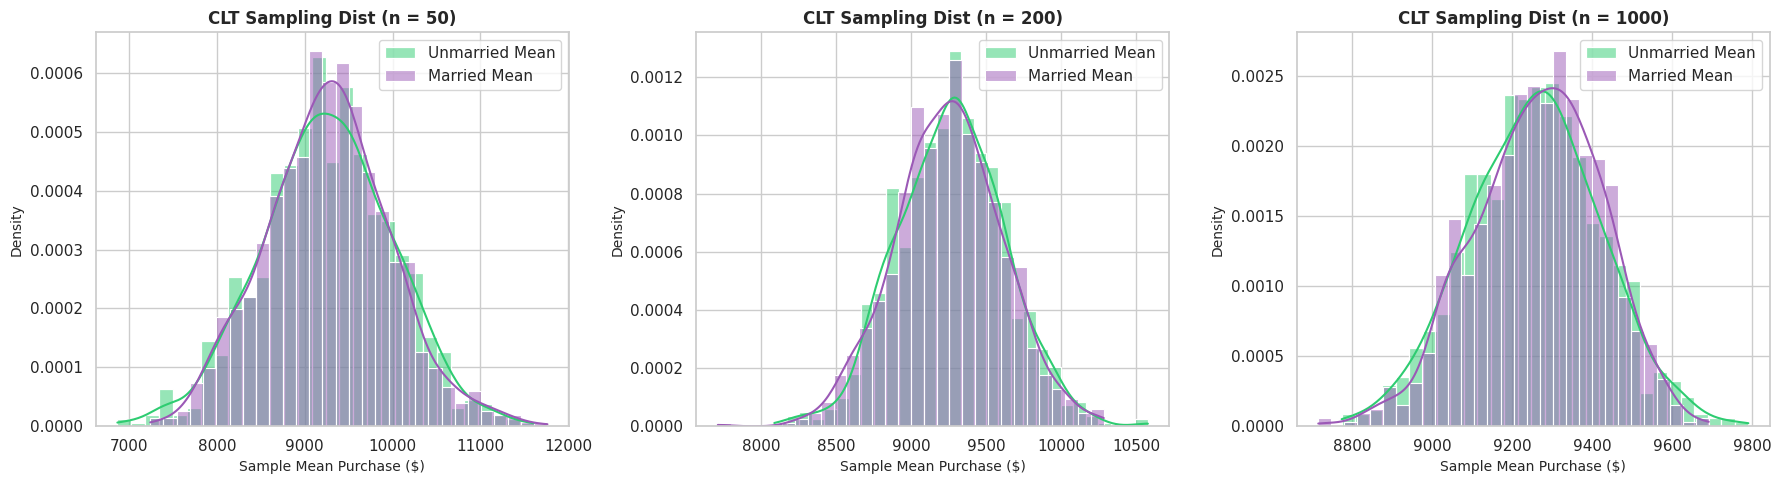

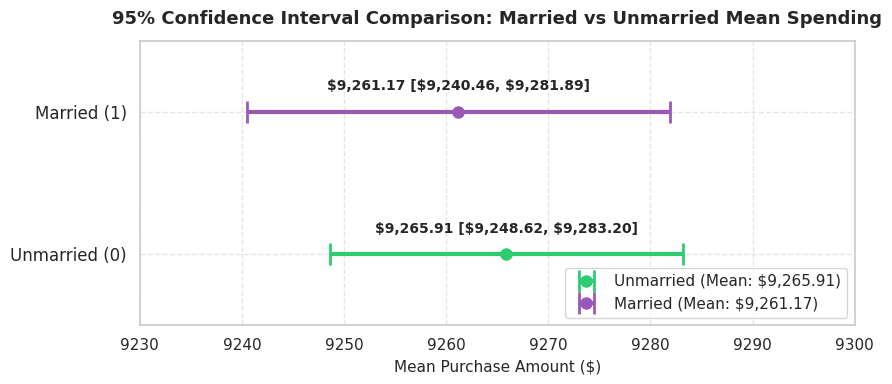

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

# 1. Extract transaction arrays by Marital Status (0: Unmarried, 1: Married)
unmarried_data = df[df['Marital_Status'] == 0]['Purchase'].values
married_data = df[df['Marital_Status'] == 1]['Purchase'].values

# 2. Compute sample statistics and standard errors
n_u, mean_u, std_u = len(unmarried_data), np.mean(unmarried_data), np.std(unmarried_data, ddof=1)
n_m, mean_m, std_m = len(married_data), np.mean(married_data), np.std(married_data, ddof=1)
se_u = std_u / np.sqrt(n_u)
se_m = std_m / np.sqrt(n_m)

# 3. Calculate Confidence Intervals across 90%, 95%, and 99% levels
conf_levels = [0.90, 0.95, 0.99]
marital_ci_records = []

for conf in conf_levels:
    z_crit = stats.norm.ppf((1 + conf) / 2)
    u_ci = (mean_u - z_crit * se_u, mean_u + z_crit * se_u)
    m_ci = (mean_m - z_crit * se_m, mean_m + z_crit * se_m)
    overlapping = not (u_ci[1] < m_ci[0] or m_ci[1] < u_ci[0])

    marital_ci_records.append({
        'Confidence Level': f"{int(conf * 100)}%",
        'Z-Critical': round(z_crit, 3),
        'Unmarried CI ($)': f"[${u_ci[0]:,.2f}, ${u_ci[1]:,.2f}]",
        'Married CI ($)': f"[${m_ci[0]:,.2f}, ${m_ci[1]:,.2f}]",
        'Overlapping?': 'Yes (Significant Overlap)' if overlapping else 'No'})
marital_ci_df = pd.DataFrame(marital_ci_records)
print("--- Confidence Interval Analysis: Married vs Unmarried ---")
display(marital_ci_df)

# 4. CLT Sampling Distributions (n = 50, 200, 1000)
np.random.seed(42)
sample_sizes = [50, 200, 1000]
num_simulations = 1000

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid")

for idx, size in enumerate(sample_sizes):
    u_means = [np.mean(np.random.choice(unmarried_data, size=size, replace=True)) for _ in range(num_simulations)]
    m_means = [np.mean(np.random.choice(married_data, size=size, replace=True)) for _ in range(num_simulations)]

    sns.histplot(u_means, kde=True, color='#2ecc71', label='Unmarried Mean', ax=axes[idx], stat="density", bins=30)
    sns.histplot(m_means, kde=True, color='#9b59b6', label='Married Mean', ax=axes[idx], stat="density", bins=30)

    axes[idx].set_title(f'CLT Sampling Dist (n = {size})', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Sample Mean Purchase ($)', fontsize=10)
    axes[idx].set_ylabel('Density', fontsize=10)
    axes[idx].legend(loc='upper right')

plt.tight_layout()
plt.show()
plt.close()

# 5. Visualizing 95% Confidence Intervals with Error Bars
plt.figure(figsize=(9, 4))
z95 = 1.960
err_u = z95 * se_u
err_m = z95 * se_m

plt.errorbar(mean_u, 1, xerr=err_u, fmt='o', color='#2ecc71', ecolor='#2ecc71',
             elinewidth=3, capsize=8, capthick=2, markersize=8, label=f"Unmarried (Mean: ${mean_u:,.2f})")
plt.text(mean_u, 1.15, f"${mean_u:,.2f} [${mean_u - err_u:,.2f}, ${mean_u + err_u:,.2f}]",
         ha='center', fontweight='bold', fontsize=10)
plt.errorbar(mean_m, 2, xerr=err_m, fmt='o', color='#9b59b6', ecolor='#9b59b6',
             elinewidth=3, capsize=8, capthick=2, markersize=8, label=f"Married (Mean: ${mean_m:,.2f})")
plt.text(mean_m, 2.15, f"${mean_m:,.2f} [${mean_m - err_m:,.2f}, ${mean_m + err_m:,.2f}]",
         ha='center', fontweight='bold', fontsize=10)

plt.yticks([1, 2], ['Unmarried (0)', 'Married (1)'], fontsize=12)
plt.xlim(9230, 9300)
plt.ylim(0.5, 2.5)
plt.title('95% Confidence Interval Comparison: Married vs Unmarried Mean Spending', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Mean Purchase Amount ($)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()
plt.close()

4E. Results for Age Analysis Across Life Stages (10 Points)

--- Confidence Interval Analysis Across Age Life Stages ---


,Life Stage,Transactions (n),Share (%),Mean Spend ($),Std Error ($),95% CI ($),99% CI ($)
0,0-17,15102,2.75,8933.46,41.59,"[$8,851.95, $9,014.98]","[$8,826.33, $9,040.60]"
1,18-25,99660,18.12,9169.66,15.95,"[$9,138.41, $9,200.92]","[$9,128.59, $9,210.74]"
2,26-35,219587,39.92,9252.69,10.69,"[$9,231.73, $9,273.65]","[$9,225.15, $9,280.23]"
3,36-50,155714,28.31,9295.33,12.69,"[$9,270.46, $9,320.20]","[$9,262.65, $9,328.01]"
4,51+,60005,10.91,9463.66,20.66,"[$9,423.17, $9,504.16]","[$9,410.44, $9,516.88]"


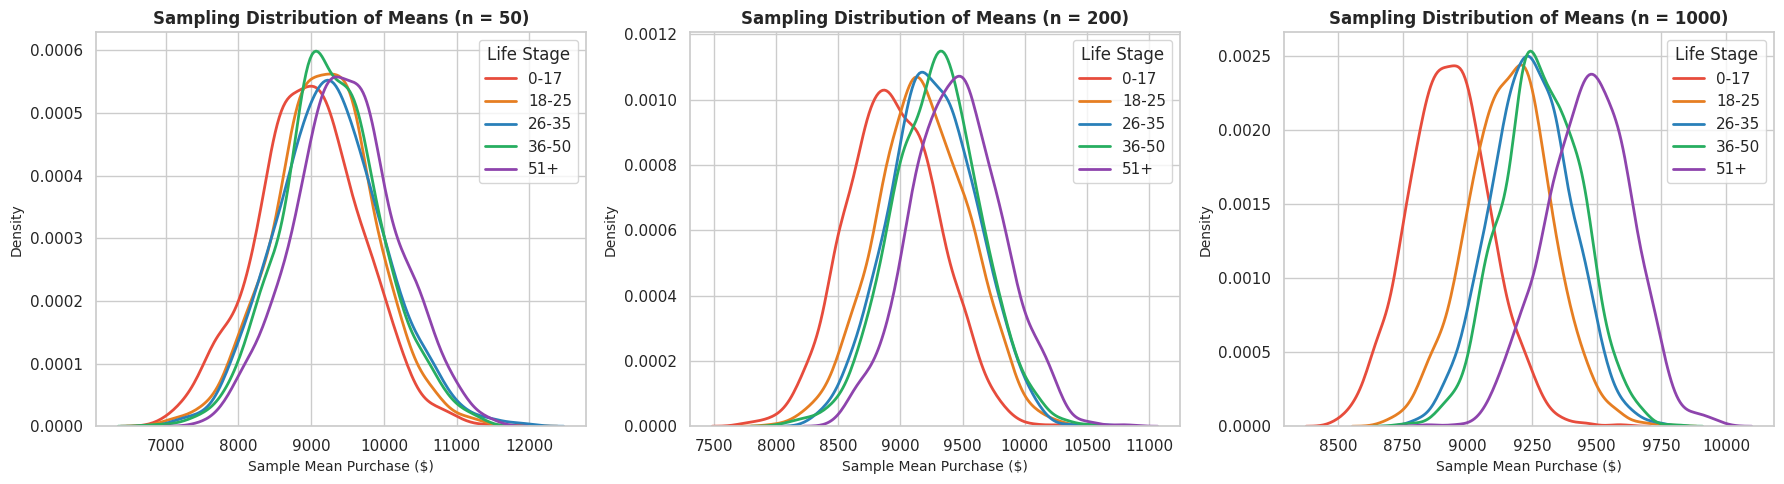

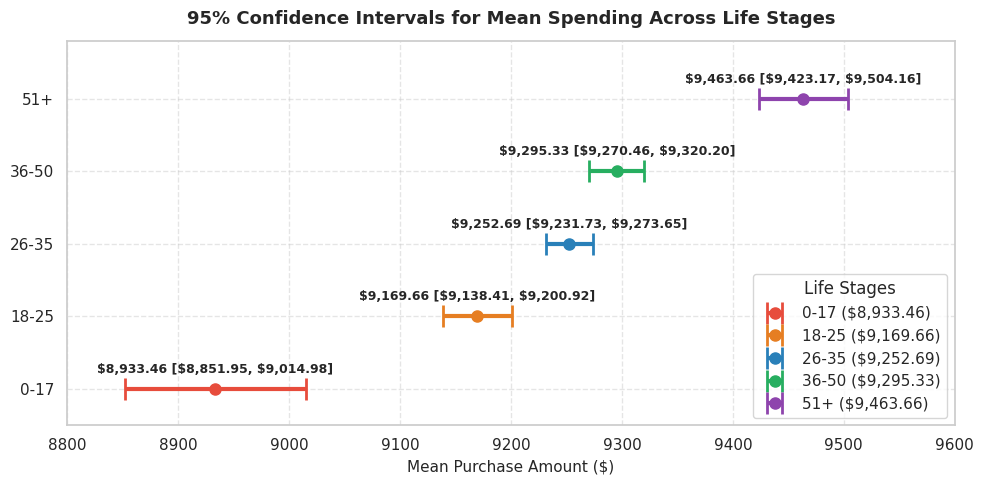

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats
import seaborn as sns

# 1. Map raw age bins into defined Life Stages as per rubric: 0-17, 18-25, 26-35, 36-50, 51+
def map_life_stages(age):
    if age == '0-17':
        return '0-17'
    elif age == '18-25':
        return '18-25'
    elif age == '26-35':
        return '26-35'
    elif age in ['36-45', '46-50']:
        return '36-50'
    elif age in ['51-55', '55+']:
        return '51+'
    return str(age)

df['Age_Life_Stage'] = df['Age'].apply(map_life_stages)
stage_order = ['0-17', '18-25', '26-35', '36-50', '51+']

# 2. Compute sample statistics and Confidence Intervals across 90%, 95%, and 99%
age_records = []
palette = ['#e74c3c', '#e67e22', '#2980b9', '#27ae60', '#8e44ad']

for stage in stage_order:
    stage_vals = df[df['Age_Life_Stage'] == stage]['Purchase'].values
    n = len(stage_vals)
    mean = np.mean(stage_vals)
    std = np.std(stage_vals, ddof=1)
    se = std / np.sqrt(n)

    # Critical z-values
    z90 = stats.norm.ppf(0.95)
    z95 = stats.norm.ppf(0.975)
    z99 = stats.norm.ppf(0.995)

    age_records.append({
        'Life Stage': stage,
        'Transactions (n)': n,
        'Share (%)': round(n / len(df) * 100, 2),
        'Mean Spend ($)': round(mean, 2),
        'Std Error ($)': round(se, 2),
        '90% CI ($)': f"[${mean - z90*se:,.2f}, ${mean + z90*se:,.2f}]",
        '95% CI ($)': f"[${mean - z95*se:,.2f}, ${mean + z95*se:,.2f}]",
        '99% CI ($)': f"[${mean - z99*se:,.2f}, ${mean + z99*se:,.2f}]",
        'mean': mean,
        'se': se,
        'ci95_low': mean - z95*se,
        'ci95_high': mean + z95*se
    })

age_ci_df = pd.DataFrame(age_records)
print("--- Confidence Interval Analysis Across Age Life Stages ---")
display(age_ci_df[['Life Stage', 'Transactions (n)', 'Share (%)', 'Mean Spend ($)', 'Std Error ($)', '95% CI ($)', '99% CI ($)']])

# 3. CLT Sampling Distributions (n = 50, 200, 1000)
np.random.seed(42)
sample_sizes = [50, 200, 1000]
num_simulations = 1000

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.set_theme(style="whitegrid")

for idx, size in enumerate(sample_sizes):
    for i, stage in enumerate(stage_order):
        stage_vals = df[df['Age_Life_Stage'] == stage]['Purchase'].values
        sampled_means = [np.mean(np.random.choice(stage_vals, size=size, replace=True)) for _ in range(num_simulations)]
        sns.kdeplot(sampled_means, label=stage, ax=axes[idx], color=palette[i], linewidth=2)

    axes[idx].set_title(f'Sampling Distribution of Means (n = {size})', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('Sample Mean Purchase ($)', fontsize=10)
    axes[idx].set_ylabel('Density', fontsize=10)
    axes[idx].legend(title='Life Stage', loc='upper right')

plt.tight_layout()
plt.show()
plt.close()

# 4. Visualizing 95% Confidence Intervals with Error Bars
plt.figure(figsize=(10, 5))
for idx, row in enumerate(age_records):
    y = idx + 1
    m = row['mean']
    err = 1.960 * row['se']
    plt.errorbar(m, y, xerr=err, fmt='o', color=palette[idx], ecolor=palette[idx],
                 elinewidth=3, capsize=8, capthick=2, markersize=8, label=f"{row['Life Stage']} (${m:,.2f})")
    plt.text(m, y + 0.22, f"${m:,.2f} [${row['ci95_low']:,.2f}, ${row['ci95_high']:,.2f}]",
             ha='center', fontweight='bold', fontsize=9)

plt.yticks(range(1, len(stage_order) + 1), stage_order, fontsize=11)
plt.xlim(8800, 9600)
plt.ylim(0.5, len(stage_order) + 0.8)
plt.title('95% Confidence Intervals for Mean Spending Across Life Stages', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Mean Purchase Amount ($)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='lower right', title='Life Stages')
plt.tight_layout()
plt.show()
plt.close()

5A. Comments on the Distribution of the Variables and Relationship Between Them

In [ ]:
import pandas as pd

# Summary of distributional shape metrics and pairwise correlations
dist_metrics = pd.DataFrame({
    'Variable': ['Purchase', 'Product_Category', 'Occupation', 'Marital_Status'],
    'Mean': [df['Purchase'].mean(), df['Product_Category'].astype(int).mean(), df['Occupation'].astype(int).mean(), df['Marital_Status'].astype(int).mean()],
    'Median': [df['Purchase'].median(), df['Product_Category'].astype(int).median(), df['Occupation'].astype(int).median(), df['Marital_Status'].astype(int).median()],
    'Skewness': [df['Purchase'].skew(), df['Product_Category'].astype(int).skew(), df['Occupation'].astype(int).skew(), df['Marital_Status'].astype(int).skew()],
    'Correlation with Purchase (r)': [
        1.000,
        df[['Product_Category', 'Purchase']].astype(int).corr().iloc[0, 1],
        df[['Occupation', 'Purchase']].astype(int).corr().iloc[0, 1],
        df[['Marital_Status', 'Purchase']].astype(int).corr().iloc[0, 1]
    ]
}).round(3)

print("--- Distributional Profiles & Correlation with Purchase ---")
display(dist_metrics)

--- Distributional Profiles & Correlation with Purchase ---


,Variable,Mean,Median,Skewness,Correlation with Purchase (r)
0,Purchase,9263.969,8047.0,0.600,1.000
1,Product_Category,5.404,5.0,1.026,-0.344
2,Occupation,8.077,7.0,0.400,0.021
3,Marital_Status,0.410,0.0,0.367,-0.000


5B. Comments for Each Univariate and Bivariate Plot

In [ ]:
import pandas as pd

# Tabular summary consolidating structural observations across all generated plots
plot_insights_summary = pd.DataFrame({
    'Analysis Type': [
        'Univariate (KDE & Histogram)',
        'Univariate (Bracket Countplot)',
        'Bivariate (Gender Boxplot)',
        'Bivariate (Age Boxplot)',
        'Bivariate (City Boxplot)',
        'Bivariate (Marital Status Boxplot)',
        'Bivariate (Correlation Heatmap)',
        'Multivariate (Pairplot Matrix)'
    ],
    'Target Attributes': [
        'Purchase Amount',
        'Spend Brackets ($0-5k to $20k+)',
        'Gender vs Purchase',
        'Age Cohorts vs Purchase',
        'City Category vs Purchase',
        'Marital Status vs Purchase',
        'Demographics & Product Category vs Spend',
        'Demographics, SKU Category, & Spend by Gender'
    ],
    'Core Empirical Observation': [
        'Positive right-skew (+0.60); primary peak at $6k-$8k; secondary peak at $15k-$16k.',
        'Modal cluster in $5k-$10k range; high-ticket transactions (>$20k) account for <0.5%.',
        'Near-identical IQRs (~$6,231); males have a slightly higher mean ($9,438 vs $8,735).',
        'Medians remain flat across all cohorts ($7,986 to $8,130); negligible variance.',
        'City C exhibits elevated median ($8,585) vs City A ($7,931) and City B ($8,005).',
        'Identical medians ($8,044 unmarried vs $8,051 married); overlapping distributions.',
        'Product Category is the sole correlate (r = -0.344); demographic features show r ~ 0.',
        'Parallel scatter stripes show no demographic segregation; male/female points overlap.'
    ]
})

print("--- Comprehensive Synthesis of Visual Exploratory Plots ---")
display(plot_insights_summary)

--- Comprehensive Synthesis of Visual Exploratory Plots ---


,Analysis Type,Target Attributes,Core Empirical Observation
0,Univariate (KDE & Histogram),Purchase Amount,Positive right-skew (+0.60); primary peak at $...
1,Univariate (Bracket Countplot),Spend Brackets ($0-5k to $20k+),Modal cluster in $5k-$10k range; high-ticket t...
2,Bivariate (Gender Boxplot),Gender vs Purchase,"Near-identical IQRs (~$6,231); males have a sl..."
3,Bivariate (Age Boxplot),Age Cohorts vs Purchase,"Medians remain flat across all cohorts ($7,986..."
4,Bivariate (City Boxplot),City Category vs Purchase,"City C exhibits elevated median ($8,585) vs Ci..."
5,Bivariate (Marital Status Boxplot),Marital Status vs Purchase,"Identical medians ($8,044 unmarried vs $8,051 ..."
6,Bivariate (Correlation Heatmap),Demographics & Product Category vs Spend,Product Category is the sole correlate (r = -0...
7,Multivariate (Pairplot Matrix),"Demographics, SKU Category, & Spend by Gender",Parallel scatter stripes show no demographic s...


5C. Comments on Different Variables When Generalizing It for Population

In [ ]:
import numpy as np
import pandas as pd
import scipy.stats as stats

# Define population extrapolation function using CLT
def generate_population_ci(data_series, group_name="Population", conf_level=0.95):
    n = len(data_series)
    mean = data_series.mean()
    std = data_series.std(ddof=1)
    se = std / np.sqrt(n)
    z = stats.norm.ppf((1 + conf_level) / 2)
    ci_lower = mean - z * se
    ci_upper = mean + z * se
    return {
        'Variable / Segment': group_name,
        'Sample Size (n)': f"{n:,}",
        'Sample Mean ($)': round(mean, 2),
        'Std Error (SE)': round(se, 2),
        f'{int(conf_level*100)}% CI Lower ($)': round(ci_lower, 2),
        f'{int(conf_level*100)}% CI Upper ($)': round(ci_upper, 2),
        'Margin of Error (±$)': round(z * se, 2)
    }

# Compute population estimations across macro categories
pop_insights = []
pop_insights.append(generate_population_ci(df['Purchase'], "Overall Black Friday Shoppers"))
pop_insights.append(generate_population_ci(df[df['Gender'] == 'M']['Purchase'], "Male Shoppers"))
pop_insights.append(generate_population_ci(df[df['Gender'] == 'F']['Purchase'], "Female Shoppers"))
pop_insights.append(generate_population_ci(df[df['Marital_Status'] == 0]['Purchase'], "Unmarried Shoppers"))
pop_insights.append(generate_population_ci(df[df['Marital_Status'] == 1]['Purchase'], "Married Shoppers"))
pop_insights.append(generate_population_ci(df[df['City_Category'] == 'A']['Purchase'], "City Category A"))
pop_insights.append(generate_population_ci(df[df['City_Category'] == 'B']['Purchase'], "City Category B"))
pop_insights.append(generate_population_ci(df[df['City_Category'] == 'C']['Purchase'], "City Category C"))

pop_generalization_df = pd.DataFrame(pop_insights)
print("--- Population Parameter Estimates via Central Limit Theorem (CLT) ---")
display(pop_generalization_df)

--- Population Parameter Estimates via Central Limit Theorem (CLT) ---


,Variable / Segment,Sample Size (n),Sample Mean ($),Std Error (SE),95% CI Lower ($),95% CI Upper ($),Margin of Error (±$)
0,Overall Black Friday Shoppers,"550,068",9263.97,6.77,9250.69,9277.24,13.27
1,Male Shoppers,"414,259",9437.53,7.91,9422.02,9453.03,15.51
2,Female Shoppers,"135,809",8734.57,12.94,8709.21,8759.92,25.35
3,Unmarried Shoppers,"324,731",9265.91,8.82,9248.62,9283.20,17.29
4,Married Shoppers,"225,337",9261.17,10.57,9240.46,9281.89,20.71
5,City Category A,"147,720",8911.94,12.73,8886.99,8936.89,24.95
6,City Category B,"231,173",9151.30,10.31,9131.10,9171.50,20.20
7,City Category C,"171,175",9719.92,12.54,9695.34,9744.50,24.58
